In [ ]:
from datasets import load_dataset

ds = load_dataset("agentlans/high-quality-english-sentences")

README.md:   0%|          | 0.00/2.30k [00:00<?, ?B/s]

train.txt.gz: reconstructing file:   0%|          |  0.00B / 85.5MB            

train.txt.gz: downloading bytes:           |  0.00B            

test.txt.gz: reconstructing file:   0%|          |  0.00B / 9.49MB            

test.txt.gz: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1534699 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/170522 [00:00<?, ? examples/s]

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
print(ds["train"][0])
print(ds['train'].column_names)
print(len(ds['train']))

{'text': 'Soon we dropped into a living forest, where cold-tolerant evergreens and boreal animals still evoke the Canadian heritage of an ecosystem pushed south by glaciers 20,000 years ago.'}
['text']
1534699


In [ ]:
df =ds['train'].shuffle(seed=42).select(range(40000))
df=pd.DataFrame(df)
print(df.shape)
df.head()

(40000, 1)


,text
0,If the sender does not provide the correct inf...
1,Points Scoring Rubric 2 Sentence names the fou...
2,Mobile-friendly emails were first invented bec...
3,"Learn how to build P charts, C charts, and X-b..."
4,The country also provided links for humanitari...


In [ ]:
print(df.head(10))
print(df.info())
print(df.isnull().sum())
print(df.duplicated().sum())

print(df.columns)
print(df.iloc[0, 0])

                                                text
0  If the sender does not provide the correct inf...
1  Points Scoring Rubric 2 Sentence names the fou...
2  Mobile-friendly emails were first invented bec...
3  Learn how to build P charts, C charts, and X-b...
4  The country also provided links for humanitari...
5                 Soliloquy of the Spanish Cloister.
6       What did we talk about before we had babies?
7  Storing a copy of the data in multiple Windows...
8  Workers' compensation claims rates for occasio...
9  Standing firmly against the creation of new di...
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    40000 non-null  object
dtypes: object(1)
memory usage: 312.6+ KB
None
text    0
dtype: int64
0
Index(['text'], dtype='object')
If the sender does not provide the correct information, the transaction cannot be completed.


In [ ]:
import re

def clean_text(text):
  text = text.lower()
  text =re.sub(r'\s+',' ',text)
  text = text.strip()
  return text

df['clean_text']=df['text'].apply(clean_text)
df[['clean_text']].head(1)

,clean_text
0,if the sender does not provide the correct inf...


In [ ]:
df['word_count'] = df['clean_text'].apply(
    lambda x:len(x.split())
)
df['word_count'].describe()



,word_count
count,40000.000000
mean,21.495575
std,11.128260
min,1.000000
25%,14.000000
50%,20.000000
75%,27.000000
max,155.000000


In [ ]:
df = df[
    (df['word_count'] >= 5) &
    (df['word_count'] <= 60)
].copy()

df = df.reset_index(drop=True)

print("Remaining records:", len(df))

Remaining records: 39265


In [ ]:
print(df['word_count'].describe())
print(df[['clean_text', 'word_count']].head(10))

count    39265.000000
mean        21.366026
std         10.186459
min          5.000000
25%         14.000000
50%         20.000000
75%         27.000000
max         60.000000
Name: word_count, dtype: float64
                                          clean_text  word_count
0  if the sender does not provide the correct inf...          14
1  points scoring rubric 2 sentence names the fou...          15
2  mobile-friendly emails were first invented bec...          17
3  learn how to build p charts, c charts, and x-b...          19
4  the country also provided links for humanitari...          13
5                 soliloquy of the spanish cloister.           5
6       what did we talk about before we had babies?           9
7  storing a copy of the data in multiple windows...          24
8  workers' compensation claims rates for occasio...          22
9  standing firmly against the creation of new di...          49


In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer

vocab_size = 20000

tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>")
tokenizer.fit_on_texts(df['clean_text'])

word_index = tokenizer.word_index

print(len(word_index))
list(word_index.items())[:10]

48498


[('<OOV>', 1),
 ('the', 2),
 ('of', 3),
 ('and', 4),
 ('to', 5),
 ('in', 6),
 ('a', 7),
 ('is', 8),
 ('that', 9),
 ('for', 10)]

In [ ]:
input_seq = tokenizer.texts_to_sequences(df['clean_text'])
for i in range(3):
  print(input_seq[i])

[51, 2, 1, 180, 27, 163, 2, 1397, 93, 2, 6743, 646, 17, 1924]
[991, 10777, 14378, 137, 2824, 1585, 2, 835, 4, 874, 34, 63, 10, 7, 2383]
[966, 1804, 7141, 38, 68, 4459, 87, 764, 38, 10778, 42, 27, 117, 294, 5, 276, 93, 3244]


In [ ]:
X = []
y = []

for seq in input_seq:
  for i in range(1, len(seq)):
    input_seq = seq[:i]
    output_seq =seq[i]

    X.append(input_seq)
    y.append(output_seq)

print(len(X))
print(len(y))




810641
810641


In [ ]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_len = max(len(seq) for seq in X)

X=pad_sequences(X, maxlen=max_len, padding='post')
print(X.shape)
print(X[:5])



(810641, 63)
[[ 51   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0]
 [ 51   2   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0]
 [ 51   2   1   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0]
 [ 51   2   1 180   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   

In [ ]:
X=np.array(X)
y=np.array(y)
print(X.shape)
print(y.shape)

(810641, 63)
(810641,)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense,Dropout

model = Sequential([
    Embedding(
        input_dim=20000,
        output_dim=100,
        mask_zero=True
    ),
    LSTM(150),
    Dropout(0.3),
    Dense(20000, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
history = model.fit(
    X,
    y,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

Epoch 1/10
5067/5067 ━━━━━━━━━━━━━━━━━━━━ 92s 17ms/step - accuracy: 0.1077 - loss: 6.9523 - val_accuracy: 0.1360 - val_loss: 6.5492
Epoch 2/10
5067/5067 ━━━━━━━━━━━━━━━━━━━━ 83s 16ms/step - accuracy: 0.1470 - loss: 6.4244 - val_accuracy: 0.1542 - val_loss: 6.3106
Epoch 3/10
5067/5067 ━━━━━━━━━━━━━━━━━━━━ 142s 16ms/step - accuracy: 0.1618 - loss: 6.1599 - val_accuracy: 0.1620 - val_loss: 6.1970
Epoch 4/10
5067/5067 ━━━━━━━━━━━━━━━━━━━━ 84s 16ms/step - accuracy: 0.1711 - loss: 5.9661 - val_accuracy: 0.1671 - val_loss: 6.1303
Epoch 5/10
5067/5067 ━━━━━━━━━━━━━━━━━━━━ 83s 16ms/step - accuracy: 0.1784 - loss: 5.8009 - val_accuracy: 0.1698 - val_loss: 6.0888
Epoch 6/10
5067/5067 ━━━━━━━━━━━━━━━━━━━━ 83s 16ms/step - accuracy: 0.1849 - loss: 5.6515 - val_accuracy: 0.1714 - val_loss: 6.0756
Epoch 7/10
5067/5067 ━━━━━━━━━━━━━━━━━━━━ 83s 16ms/step - accuracy: 0.1907 - loss: 5.5139 - val_accuracy: 0.1709 - val_loss: 6.0810
Epoch 8/10
5067/5067 ━━━━━━━━━━━━━━━━━━━━ 83s 16ms/step - accuracy: 0.1962 

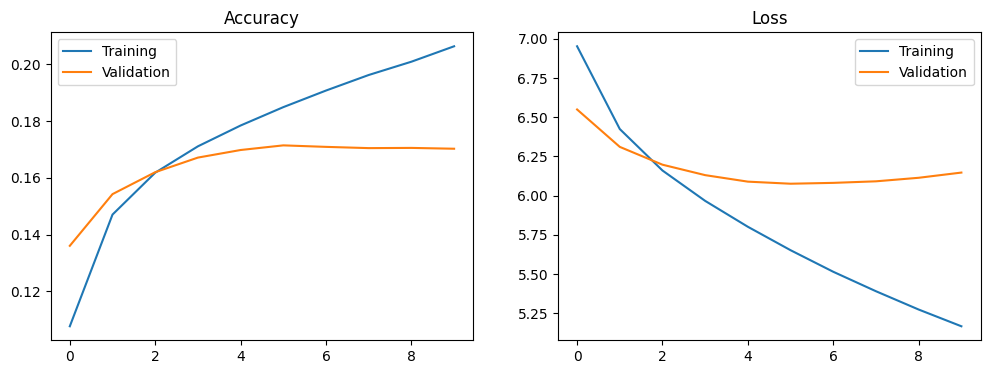

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Loss')
plt.legend()

plt.show()

In [ ]:
def predict_next_word(text):
    token_list = tokenizer.texts_to_sequences([text])[0]

    token_list = pad_sequences(
        [token_list],
        maxlen=max_len - 1,
        padding='post'
    )

    predicted = model.predict(token_list, verbose=0)

    predicted_word_index = np.argmax(predicted)

    predicted_word = tokenizer.index_word.get(
        predicted_word_index, "Unknown"
    )

    return predicted_word

In [ ]:
text = "the world is  "

print("Next word:", predict_next_word(text))

Next word: a


In [ ]:
model.save("next_word_model.keras")

In [ ]:
import pickle

with open("tokenizer.pkl", "wb") as file:
    pickle.dump(tokenizer, file)

In [ ]:
with open("max_len.pkl", "wb") as file:
    pickle.dump(max_len, file)

In [ ]:
from google.colab import files

files.download("next_word_model.keras")
files.download("tokenizer.pkl")
files.download("max_len.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>